# Running with METISSE

In this tutorial, we will be running BackPop with the stellar engine METISSE (**MET**hod of **I**nterpolation for **S**ingle **S**tar **E**volution). This method was designed by [Agrawal et al. (2025)](https://ui.adsabs.harvard.edu/abs/2025JOSS...10.8817A/abstract), and you can read the docs [here](https://metisse.readthedocs.io/en/latest/index.html#).


## Imports

Here we import the two main classes of BackPop and corner to plot our results.

In [1]:
import corner

from backpop import BackPop
from backpop import BackPopsteriors

## Ini file

## Running BackPop

In [2]:
bp = BackPop(config_file='../../../example_inis/simple_METISSE.ini')

bp.run_sampler()

Initializing BackPop with simple_METISSE.ini
Running sampling using multiprocessing with 2 threads
Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 26     | 1        | 4        | 39500    | N/A    | 8042  | -15.79   


## Load in results

In [6]:
posteriors = BackPopsteriors(file='../../../example_inis/simple_METISSE_output/posteriors.h5')

BPP = posteriors.bpp
kick_info = posteriors.kick_info

## Initial Conditions

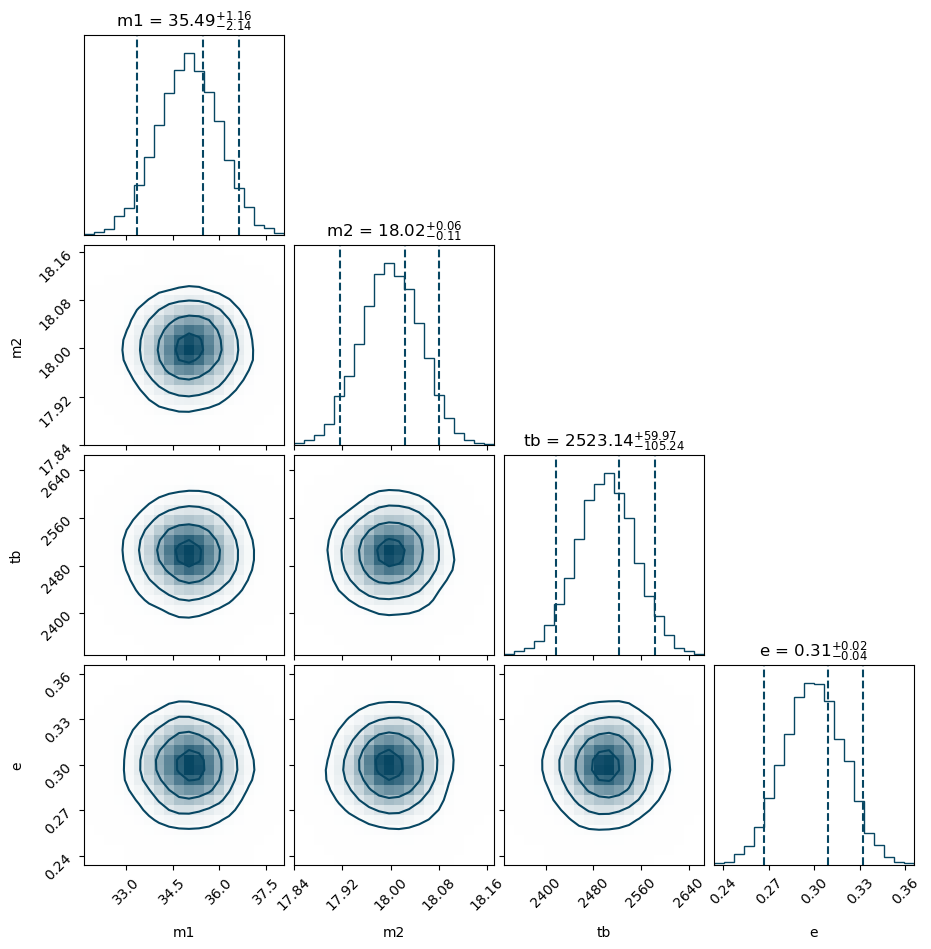

In [7]:
fig = posteriors.cornerplot(quantiles=[0.05,0.68,0.95],
                            show_titles=True,
                            smooth=True,
                            plot_contours=True,
                            fill_contours=False,
                            plot_datapoints=False,
                            )

## Binary Selection

In [8]:
MS_select= BPP.loc[(BPP.kstar_1.isin([0, 1]) & (BPP.kstar_2.isin([0, 1])))]

In [9]:
print('Unique kstar_1 values:', MS_select.kstar_1.unique())
print('Unique kstar_2 values:', MS_select.kstar_2.unique())

MS_select[['kstar_1', 'kstar_2']]

Unique kstar_1 values: [1.]
Unique kstar_2 values: [1.]


,kstar_1,kstar_2
99,1.0,1.0
100,1.0,1.0
101,1.0,1.0
102,1.0,1.0
103,1.0,1.0
...,...,...
10195,1.0,1.0
10196,1.0,1.0
10197,1.0,1.0
10198,1.0,1.0


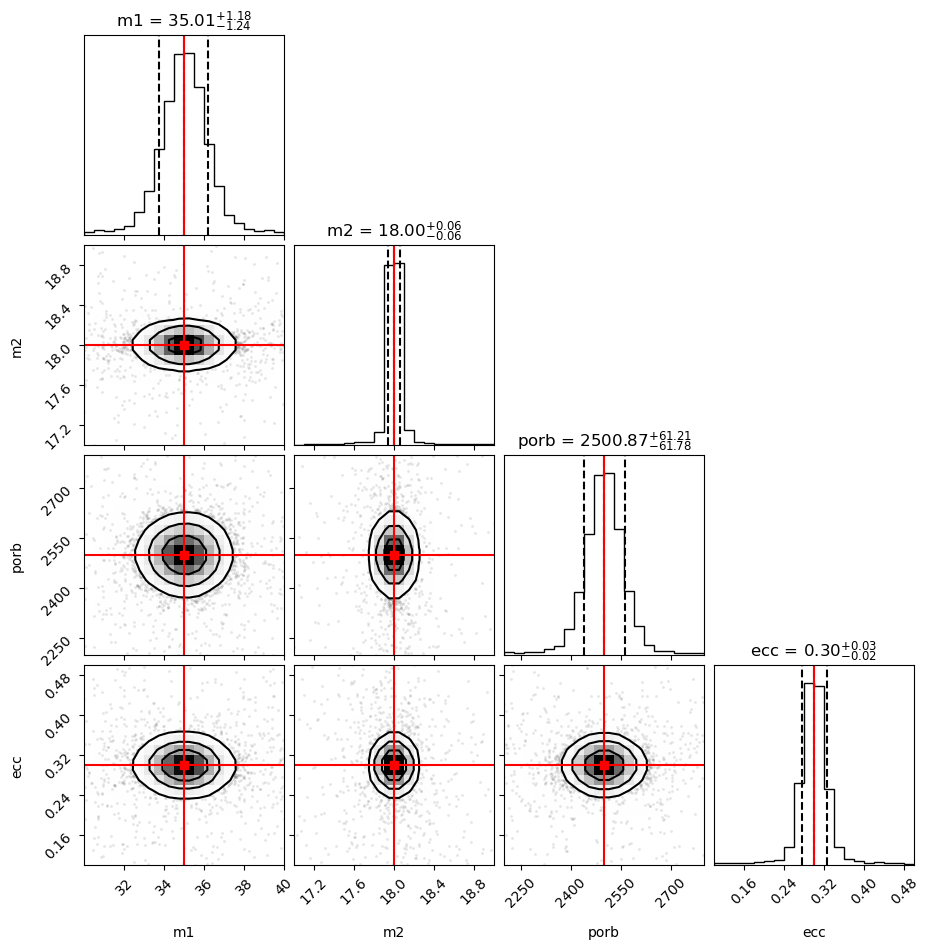

In [29]:
figure = corner.corner(MS_select[['mass_1', 'mass_2', 'porb', 'ecc']],
                        truths=[35, 18, 2500, 0.3],
                        truth_color='red',
                        smooth=True,
                        labels=['m1', 'm2', 'porb', 'ecc'], 
                        show_titles=True,
                        title_kwargs={"fontsize": 12},
                        quantiles=[0.16, 0.5, 0.84],
                        range=[[30,40], [17, 19], [2200,2800], [0.1,0.5]]
                        )

In [30]:
HGMS_select = BPP.loc[((BPP.kstar_1 == 2) & (BPP.kstar_2 == 1))]

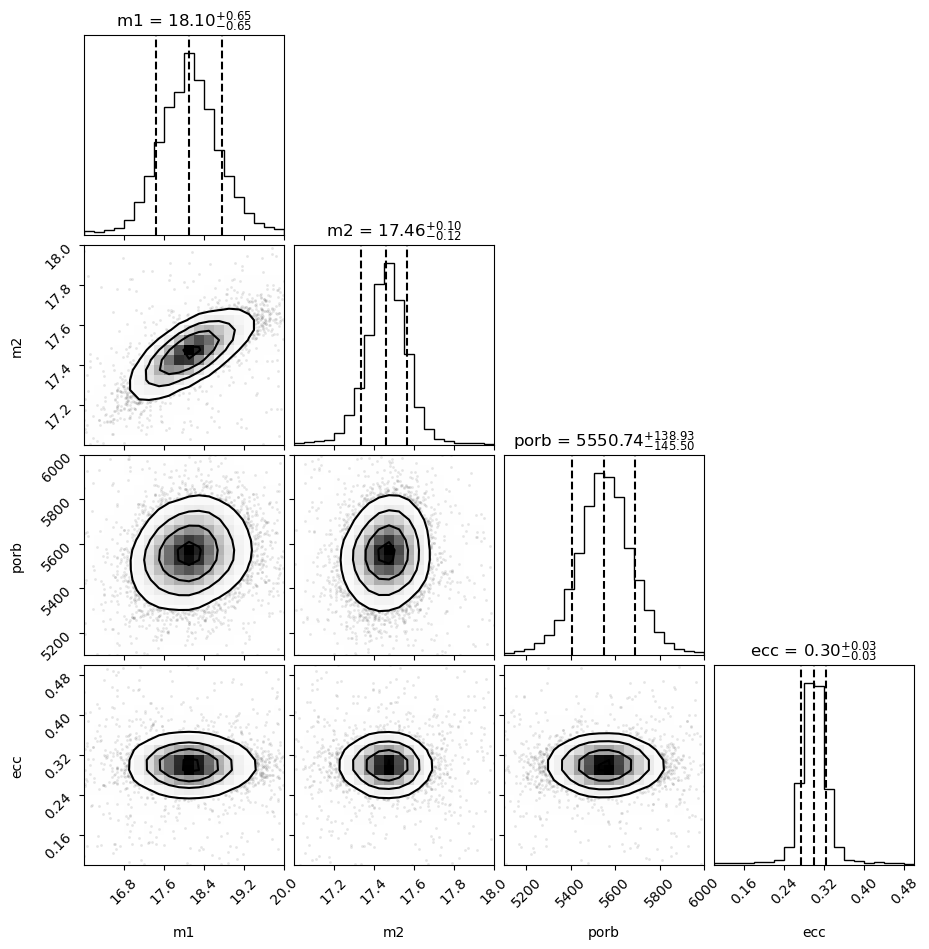

In [31]:
figure = corner.corner(HGMS_select[['mass_1', 'mass_2', 'porb', 'ecc']],
                        smooth=True,
                        labels=['m1', 'm2', 'porb', 'ecc'], 
                        show_titles=True,
                        title_kwargs={"fontsize": 12},
                        quantiles=[0.16, 0.5, 0.84],
                        range=[[16,20], [17, 18], [5100,6000], [0.1,0.5]]
                        )